# 02 — Bifurcation: who resists forever and who falls

Under constant usage the model is linear in $C$:

$$\frac{dC}{dt} = a\,C + b,\qquad a = \alpha u A \beta + \gamma W,\qquad b = \alpha u A - \gamma W.$$

It has one interior equilibrium, the **point of no return**

$$C_u = \frac{\gamma W - \alpha u A}{\alpha u A \beta + \gamma W},$$

which is unstable because $a > 0$. The clamp at zero adds a second equilibrium, $C = 0$, which is stable while $b < 0$. This notebook sweeps ambition $A$ and feedback $\beta$ to map both.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from corruption.bifurcation import critical_ambition, fate_boundary_ambition, sweep
from corruption.model import BearerParams, constant_usage, rhs
from corruption.plotting import plot_bifurcation, plot_fate_map

FIGURES = Path("../docs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
base = BearerParams(W=0.6, A=0.5, c0=0.05)
print(f"critical ambition A_c = γW/(αu) = {critical_ambition(base):.3f}")

critical ambition A_c = γW/(αu) = 0.600


## Phase line

The sign of $dC/dt$ tells the story. Below $C_u$ the drift is negative and the clamp holds the bearer at $C = 0$. Above $C_u$ the drift is positive and grows with $C$, so the bearer falls. As $A$ rises, $C_u$ slides down to zero and the resisting basin shrinks to nothing.

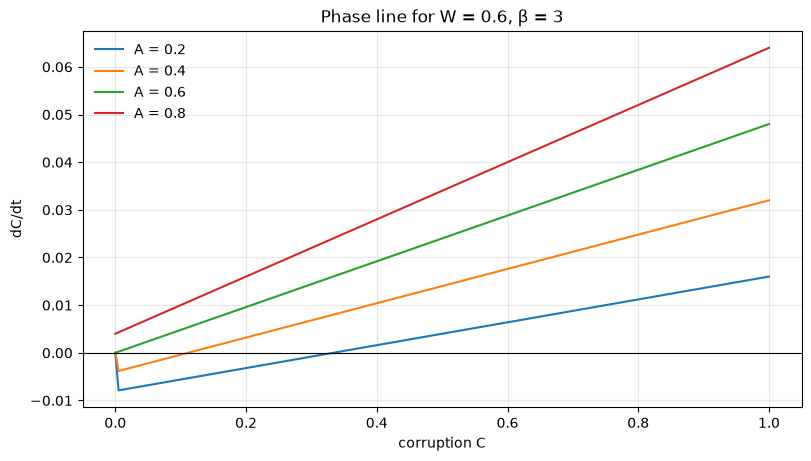

In [2]:
c = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for A in (0.2, 0.4, 0.6, 0.8):
    p = BearerParams(W=base.W, A=A)
    ax.plot(c, [rhs(0.0, ci, p, constant_usage(1.0)) for ci in c], label=f"A = {A}")
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="corruption C", ylabel="dC/dt", title="Phase line for W = 0.6, β = 3")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

## Bifurcation diagram

Equilibria against ambition, for four values of $\beta$. The stable branch $C = 0$ exists only for $A < A_c$. The unstable branch $C_u$ starts at 1 when $A = 0$ and hits 0 at $A_c$ for every $\beta$: **the critical ambition does not depend on feedback**. What $\beta$ changes is how fast $C_u$ drops, which is how much initial corruption a bearer can carry and still recover.

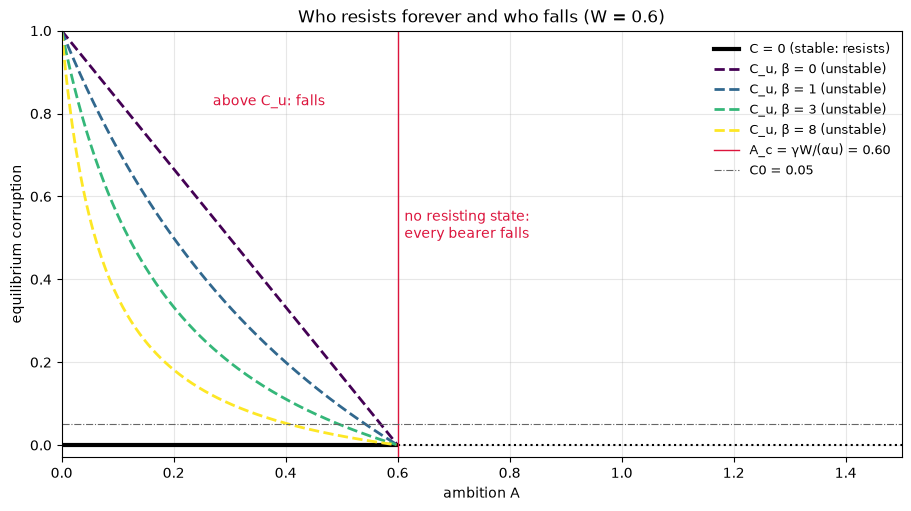

In [3]:
A_values = np.linspace(0, 1.5, 400)
fig = plot_bifurcation(base, A_values, betas=[0.0, 1.0, 3.0, 8.0])
fig.savefig(FIGURES / "bifurcation.png", dpi=150)
plt.show()

## Fate map over $(A, \beta)$

A bearer who starts at $C_0$ falls when $C_0 > C_u$, which happens above the fate boundary

$$A_f(\beta) = \frac{\gamma W (1 - C_0)}{\alpha u (1 + \beta C_0)}.$$

For $C_0 > 0$ this boundary bends left as $\beta$ grows: feedback turns a small head start in corruption into a fall. For $C_0 = 0$ it collapses to $A_c$.

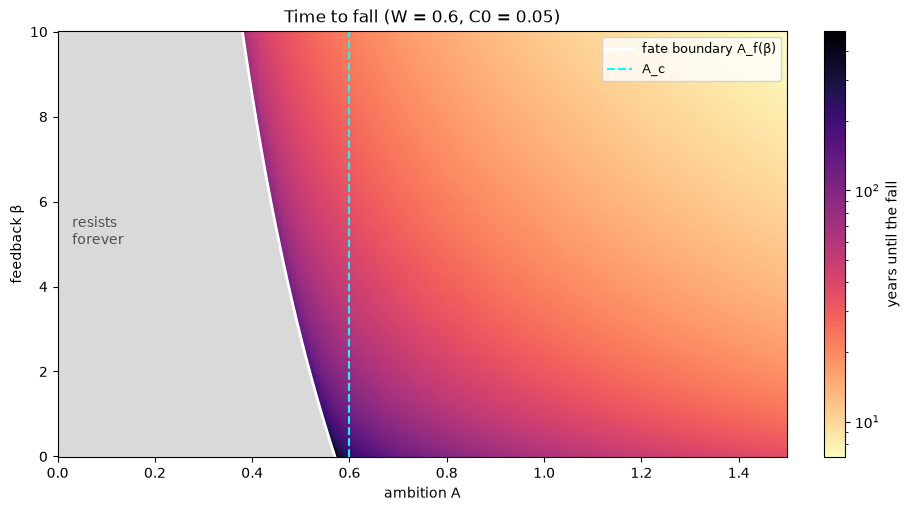

In [4]:
result = sweep(base, np.linspace(0.0, 1.5, 300), np.linspace(0.0, 10.0, 200))
fig = plot_fate_map(result, base)
fig.savefig(FIGURES / "fate_map.png", dpi=150)
plt.show()

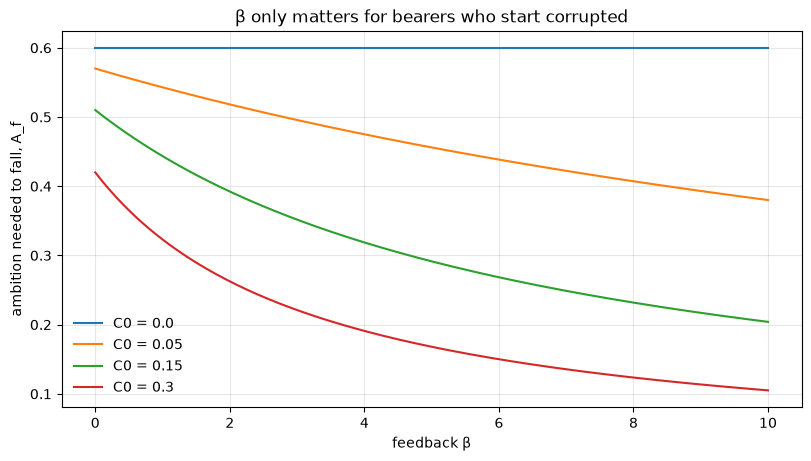

In [5]:
betas = np.linspace(0, 10, 200)
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for c0 in (0.0, 0.05, 0.15, 0.3):
    p = BearerParams(W=base.W, A=0.5, c0=c0)
    ax.plot(betas, fate_boundary_ambition(p, betas), label=f"C0 = {c0}")
ax.set(
    xlabel="feedback β",
    ylabel="ambition needed to fall, A_f",
    title="β only matters for bearers who start corrupted",
)
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

## Takeaways

- The point of no return exists even without feedback ($\beta = 0$): the recovery term $\gamma W(1 - C)$ weakens as corruption grows, which is positive feedback on its own.
- $A_c = \gamma W / (\alpha u)$ is the bifurcation point. Above it no bearer resists, whatever $\beta$.
- $\beta$ moves the fate boundary only through $C_0$. A bearer's intent when taking the ring (their initial corruption) and the strength of feedback act together.